In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style='whitegrid')

# Load dataset
df = pd.read_csv('Titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
# Dataset dimensions, column types, and non-null counts
print("Shape:", df.shape)
df.info()

# Summary statistics for numerical and categorical columns
display(df.describe(include='all'))

# Count missing values per column
print("\nMissing values per column:")
print(df.isnull().sum())

Shape: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN



Missing values per column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


**Dataset Overview:** There are 891 rows (passengers) and 12 columns containing a mix of numerical (Age, Fare, SibSp, Parch), categorical (Sex, Embarked, Pclass), and text/identifier (Name, Ticket, Cabin, PassengerId) features. Overall, only 38.4% (342 of 891) of passengers survived.

**Missing Values:**

Cabin: 687 missing (~77.1%) — far too incomplete to impute reliably, so it should either be dropped or converted into a binary Has_Cabin indicator.

Age: 177 missing (~19.9%) — can be imputed using the median age (or median age grouped by Pclass and Sex) for analysis.

Embarked: 2 missing (~0.2%) — can be filled with the mode ('S', Southampton).

Outliers (Fare & Age): Visualize Age and Fare with boxplots to spot extreme values:

Survival by Sex:
 Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

Survival by Pclass:
 Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


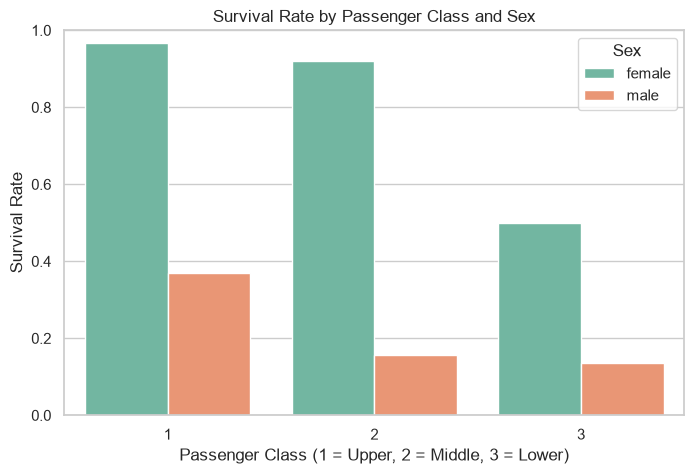

In [7]:
# Compare survival rates by Sex and Pclass
print("Survival by Sex:\n", df.groupby('Sex')['Survived'].mean())
print("\nSurvival by Pclass:\n", df.groupby('Pclass')['Survived'].mean())

# Combined view: Survival by Pclass and Sex
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', palette='Set2', errorbar=None)
plt.title('Survival Rate by Passenger Class and Sex')
plt.xlabel('Passenger Class (1 = Upper, 2 = Middle, 3 = Lower)')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)
plt.show()

**Q1:** Sex (gender) is the single strongest predictor of survival. Overall, 74.2% of females survived compared to only 18.9% of males—a gap of more than 55 percentage points.

Even when broken down by class, 1st-class females (96.8%) and 2nd-class females (92.1%) had overwhelmingly higher survival rates than 1st-class males (36.9%), showing that sex outweighed socioeconomic status as the primary survival determinant.

C:\Users\lizmo\AppData\Local\Temp\ipykernel_42644\790917490.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Pclass', y='Survived', palette='Blues_d', errorbar=None, ax=ax[1])


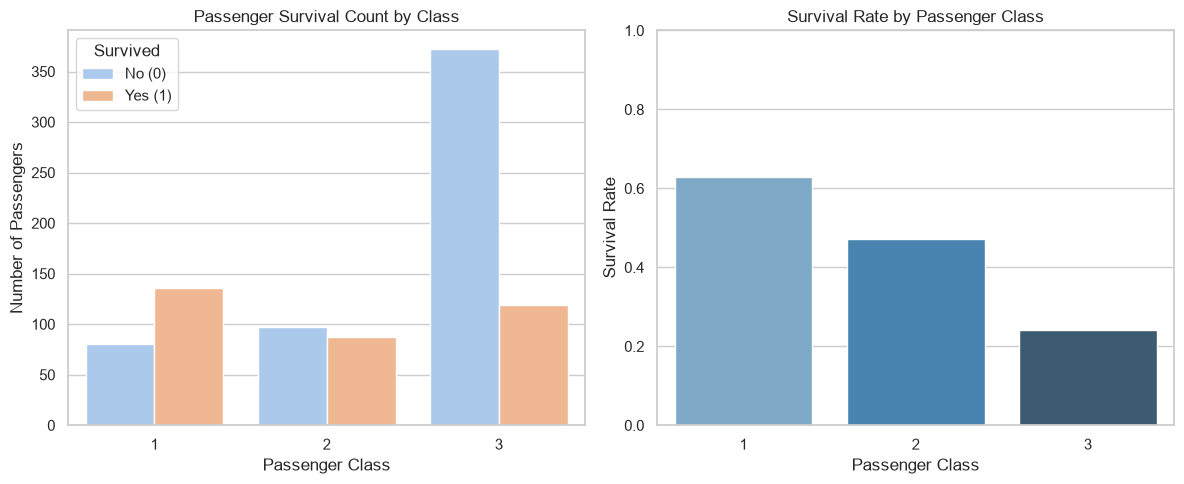

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Count of survivors vs non-survivors by Pclass
sns.countplot(data=df, x='Pclass', hue='Survived', palette='pastel', ax=ax[0])
ax[0].set_title('Passenger Survival Count by Class')
ax[0].set_xlabel('Passenger Class')
ax[0].set_ylabel('Number of Passengers')
ax[0].legend(title='Survived', labels=['No (0)', 'Yes (1)'])

# Survival proportion by Pclass
sns.barplot(data=df, x='Pclass', y='Survived', palette='Blues_d', errorbar=None, ax=ax[1])
ax[1].set_title('Survival Rate by Passenger Class')
ax[1].set_xlabel('Passenger Class')
ax[1].set_ylabel('Survival Rate')
ax[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Q2:** Yes, the data strongly supports this. Survival rates drop sharply with passenger class:

1st Class (Upper): 63.0% survived (136 of 216)

2nd Class (Middle): 47.3% survived (87 of 184)

3rd Class (Lower): 24.2% survived (119 of 491)

               count      mean
AgeGroup                      
Child (0-12)      69  0.579710
Teen (13-18)      70  0.428571
Adult (19-60)    553  0.388788
Senior (60+)      22  0.227273


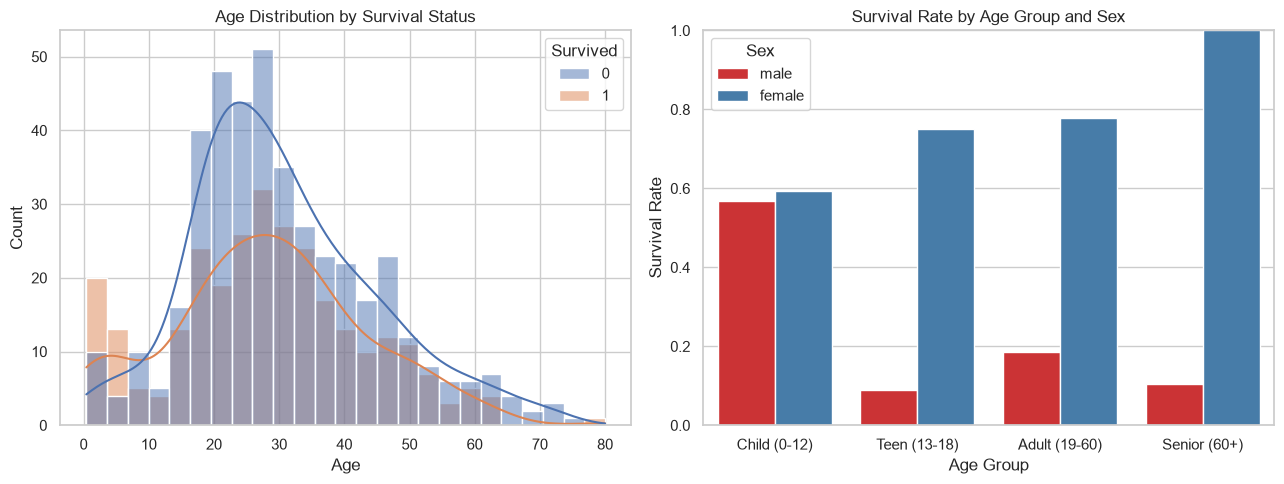

In [9]:
# Feature engineering: categorize passengers into age groups
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 18, 60, 100],
    labels=['Child (0-12)', 'Teen (13-18)', 'Adult (19-60)', 'Senior (60+)']
)

print(df.groupby('AgeGroup', observed=False)['Survived'].agg(['count', 'mean']))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Age distribution by survival
sns.histplot(data=df, x='Age', hue='Survived', bins=25, kde=True, ax=ax[0])
ax[0].set_title('Age Distribution by Survival Status')
ax[0].set_xlabel('Age')

# Survival rate by AgeGroup and Sex
sns.barplot(
    data=df, x='AgeGroup', y='Survived', hue='Sex',
    palette='Set1', errorbar=None, ax=ax[1]
)
ax[1].set_title('Survival Rate by Age Group and Sex')
ax[1].set_xlabel('Age Group')
ax[1].set_ylabel('Survival Rate')
ax[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Q3:** Yes, "women and children first" is clearly visible in the data:

Women: 74.2% of adult/all females survived versus 18.9% of males.

Children (0–12): 58.0% of children survived (40 of 69), significantly higher than teens (42.9%), adults (38.9%), and seniors (22.7%).

Notably, even among male passengers, young boys (0–12) had a much higher survival rate (~56.8%) than adult men (~16.5%), confirming that children were prioritized alongside women.

            count      mean
FamilySize                 
1             537  0.303538
2             161  0.552795
3             102  0.578431
4              29  0.724138
5              15  0.200000
6              22  0.136364
7              12  0.333333
8               6  0.000000
11              7  0.000000


C:\Users\lizmo\AppData\Local\Temp\ipykernel_42644\3153533177.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='FamilySize', y='Survived', palette='viridis', errorbar=None)


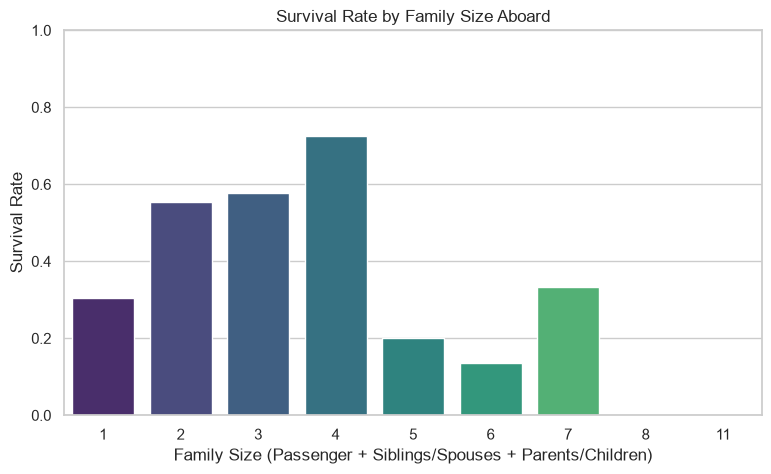

In [10]:
# Create FamilySize feature
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
print(df.groupby('FamilySize')['Survived'].agg(['count', 'mean']))

plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='FamilySize', y='Survived', palette='viridis', errorbar=None)
plt.title('Survival Rate by Family Size Aboard')
plt.xlabel('Family Size (Passenger + Siblings/Spouses + Parents/Children)')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)
plt.show()

**Q4:** Small families survived at much higher rates than solo travelers or very large families:

Passengers traveling alone (FamilySize = 1) made up the majority of the ship (537 passengers) but had only a 30.4% survival rate.

Passengers in small families of 2 to 4 people achieved the highest survival rates (55.3% for size 2, 57.8% for size 3, and 72.4% for size 4), likely because family members helped each other reach the deck and secure seats.

Survival plummeted for large families of 5 or more (dropping to 20.0% for size 5, 13.6% for size 6, and 0% for sizes 8 and 11), as larger families—mostly traveling in 3rd class—struggled to stay together and evacuate in time.